# Simulate metagenomes abundances

In [ ]:
from matplotlib.pyplot import spy
from metagenomes_simulation.generators import (
    create_block_correlation,
    create_sparse_correlation,
    create_sparse_block_correlation,
    simulate_absolute_abundances_ground_truth,
    simulate_sequencing,
)

In [2]:
BLOCKS_OTUS = [100, 20, 4, 120]
N_SAMPLES = 1000
N_COUNTS_PER_SAMPLE = 1000
N_PROCESSES = 8

# Simulating data - Blocks

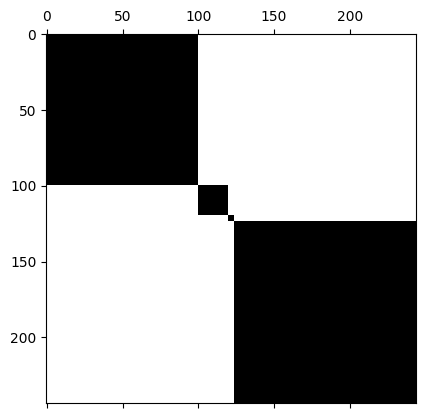

In [3]:
block_corr_matrix_ground_truth = create_block_correlation(
    block_sizes=BLOCKS_OTUS, within_correlation=0.5, between_correlation=0.0
)
spy(block_corr_matrix_ground_truth.to_numpy())

In [4]:
block_absolute_abundance_ground_truth = (
    simulate_absolute_abundances_ground_truth(
        block_corr_matrix_ground_truth,
        n_sample=N_SAMPLES,
        mean_abundance=500,
        var_abundance=0.1,
        taxa_var_abundance=2,
    )
)
block_absolute_abundance_ground_truth

,OTU_1,OTU_2,OTU_3,OTU_4,OTU_5,OTU_6,OTU_7,OTU_8,OTU_9,OTU_10,...,OTU_235,OTU_236,OTU_237,OTU_238,OTU_239,OTU_240,OTU_241,OTU_242,OTU_243,OTU_244
Sample0,247.358248,650.741986,133.346080,1349.905820,107.069917,3086.502503,2166.000023,249.562117,1283.007039,770.033348,...,95.008086,1234.144867,1338.515289,365.664525,160.064822,215.115253,341.983703,148.206542,382.479073,9281.182075
Sample1,194.390776,538.089843,166.368848,986.977060,102.659992,3196.101612,2081.817128,252.879726,948.182092,550.163303,...,79.591019,684.548327,1157.791173,194.404774,204.539682,112.099591,199.182900,127.455929,314.872656,7885.404284
Sample2,130.333670,387.204587,63.041146,416.879109,47.680503,1083.312319,985.657114,139.181318,292.616976,344.979788,...,66.728555,477.805100,1299.567351,271.572760,95.456266,147.474415,236.435861,105.461349,280.130437,7144.484016
Sample3,443.649787,1244.361825,155.559809,1277.009993,117.555963,2078.277923,3420.458295,314.465877,1205.022396,937.643744,...,81.029650,1196.642590,1007.023527,404.997227,167.074570,116.383625,146.854544,141.985986,332.565940,5981.227847
Sample4,131.121380,722.220324,109.900816,1105.088544,99.467058,1858.431663,2076.352013,222.508073,732.541504,406.205079,...,84.162022,1457.966641,1604.775692,340.805909,205.662086,167.574822,423.765024,124.835443,306.600760,12442.144974
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Sample995,178.728274,617.994634,100.888145,1034.831884,88.328121,1576.113338,1621.122617,255.487671,1096.942477,447.981610,...,144.442283,1908.746212,2181.844041,425.173287,225.888406,297.096724,401.914762,225.041626,625.812351,13305.419834
Sample996,175.651192,683.082264,122.317418,666.485582,93.863696,2017.244400,921.507058,116.525036,613.321668,599.585052,...,57.910873,1058.490058,1385.058404,220.426640,127.778273,181.997559,155.657801,120.812693,289.705736,6794.681232
Sample997,183.435684,549.628307,98.945279,752.887316,73.601544,1966.339054,1106.775093,163.027394,384.713491,365.509952,...,127.058786,1307.214806,1222.081397,236.962339,120.668671,212.347959,354.647708,112.610249,285.436907,8680.481826
Sample998,191.675003,548.330940,110.608625,840.146522,65.985198,1533.255592,1694.514938,241.327384,500.451066,639.894575,...,102.115363,868.072065,1410.713323,363.517359,181.418113,218.509694,225.984427,179.006343,270.399372,8679.755603


In [5]:
block_sequencing_df = simulate_sequencing(
    block_absolute_abundance_ground_truth,
    sequencing_depth=N_COUNTS_PER_SAMPLE,
)
block_sequencing_df

,OTU_1,OTU_2,OTU_3,OTU_4,OTU_5,OTU_6,OTU_7,OTU_8,OTU_9,OTU_10,...,OTU_235,OTU_236,OTU_237,OTU_238,OTU_239,OTU_240,OTU_241,OTU_242,OTU_243,OTU_244
Sample0,1,3,0,3,1,8,6,1,3,2,...,0,0,2,1,1,1,0,0,1,22
Sample1,0,1,0,2,2,12,12,0,3,4,...,1,6,5,1,0,1,1,0,4,24
Sample2,1,0,0,2,0,5,5,0,2,0,...,1,2,8,1,2,1,2,2,1,44
Sample3,1,5,0,2,0,5,10,3,4,1,...,0,3,2,0,0,0,0,0,0,28
Sample4,0,0,0,4,0,5,6,1,4,3,...,1,8,2,0,0,0,1,1,1,45
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Sample995,0,4,0,5,0,3,5,0,9,4,...,0,5,9,3,1,1,1,0,3,31
Sample996,1,1,0,4,0,7,3,2,2,1,...,0,5,8,2,3,1,0,0,0,25
Sample997,0,3,0,1,0,7,4,0,1,1,...,0,2,5,3,0,0,2,0,0,36
Sample998,0,2,0,3,0,6,10,0,2,3,...,0,5,4,1,1,1,0,1,2,22


# Simulationg data - Sparse

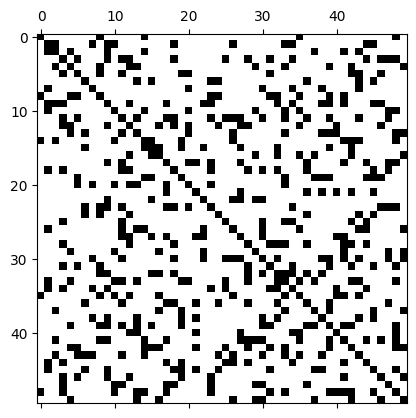

In [6]:
sparce_corr_matrix_ground_truth = create_sparse_correlation(
    n_taxa=50, density=0.2, correlation_range=(0, 0.99), negative_fraction=0.1
)
spy(sparce_corr_matrix_ground_truth.to_numpy())

In [7]:
sparce_absolute_abundance_ground_truth = (
    simulate_absolute_abundances_ground_truth(
        sparce_corr_matrix_ground_truth,
        n_sample=N_SAMPLES,
        mean_abundance=500,
        var_abundance=0.3,
        taxa_var_abundance=3,
    )
)
sparce_absolute_abundance_ground_truth

,OTU1,OTU2,OTU3,OTU4,OTU5,OTU6,OTU7,OTU8,OTU9,OTU10,...,OTU41,OTU42,OTU43,OTU44,OTU45,OTU46,OTU47,OTU48,OTU49,OTU50
Sample0,467.971045,93.640384,198.329026,4075.990281,123.633065,191.528324,155.152480,1712.890285,487.294898,9083.583891,...,2272.269400,238.069696,78.529785,140.405152,138.070396,815.932103,1257.313807,134.057175,8651.942129,184.440420
Sample1,280.113208,119.260308,108.535153,13926.175035,252.407412,209.398139,312.864239,1488.723195,508.653612,12415.933640,...,479.972246,61.804960,64.432491,300.890280,45.764195,318.961160,888.594491,108.091528,3041.622216,625.996555
Sample2,262.970366,93.487405,146.692109,27940.060798,408.550683,147.134870,391.943054,1629.077798,783.959618,9247.452711,...,1699.061211,83.808811,277.097269,295.754117,63.360298,363.166577,1805.893051,128.911593,8739.329135,165.721361
Sample3,788.692288,71.178808,157.909888,7177.240422,150.449252,131.853430,90.101164,909.759045,312.821428,49283.903609,...,909.711452,95.584515,102.997700,259.336589,189.910740,999.681061,249.718773,227.851499,3750.899834,633.037626
Sample4,347.491428,84.519310,81.249338,7196.431383,155.282231,101.495403,267.124792,2217.132251,655.765283,8581.161530,...,613.232005,68.966330,151.936068,205.638015,28.893121,246.581703,982.073687,103.141476,3998.651415,308.223136
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Sample995,438.278010,40.154549,209.690022,39136.706946,105.050795,70.350873,271.784780,2412.820242,234.413910,20778.117373,...,2246.664352,295.435463,155.981488,280.901293,66.848338,505.058169,852.502390,93.130917,6438.769876,236.645874
Sample996,734.853933,137.067091,59.804098,7035.373162,188.651215,98.368639,217.306829,1321.324805,726.158152,8770.639091,...,991.301990,175.198595,123.955896,108.105862,93.781616,456.529194,549.909665,234.813728,3670.536307,175.564743
Sample997,487.606916,51.603322,117.680544,21669.955068,292.744915,136.919777,313.997365,1622.969267,465.076044,14429.373016,...,1544.961631,116.554740,89.150938,383.136502,82.867988,660.533367,650.240801,382.428258,7862.909249,72.117777
Sample998,157.934609,97.276086,407.367328,8414.147193,312.738123,246.372069,81.281624,2122.174819,753.870102,17267.138569,...,845.473581,130.829335,106.395131,130.148148,106.181300,365.871274,1485.085134,164.902191,3176.584578,310.278749


In [8]:
sparce_sequencing_df = simulate_sequencing(
    sparce_absolute_abundance_ground_truth,
    sequencing_depth=N_COUNTS_PER_SAMPLE,
)
sparce_sequencing_df

,OTU1,OTU2,OTU3,OTU4,OTU5,OTU6,OTU7,OTU8,OTU9,OTU10,...,OTU41,OTU42,OTU43,OTU44,OTU45,OTU46,OTU47,OTU48,OTU49,OTU50
Sample0,6,3,2,47,2,1,2,14,6,140,...,21,6,1,1,2,8,21,1,110,2
Sample1,1,1,2,164,4,3,6,22,8,160,...,6,0,1,4,0,1,11,4,34,6
Sample2,0,1,0,217,6,1,2,19,8,84,...,12,1,2,2,1,8,21,2,79,1
Sample3,5,0,4,76,1,0,1,6,0,411,...,5,0,1,1,1,5,1,1,38,6
Sample4,7,2,0,99,1,2,6,32,9,105,...,7,0,3,4,1,6,11,3,47,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Sample995,2,0,4,288,3,1,3,24,1,162,...,16,4,1,2,0,3,8,0,45,2
Sample996,12,1,0,103,2,4,2,19,11,148,...,9,3,2,2,2,5,7,5,43,4
Sample997,4,0,2,241,3,0,5,16,8,166,...,14,0,2,8,1,6,8,3,87,2
Sample998,3,1,3,107,8,2,1,23,9,195,...,16,1,1,1,2,3,17,0,42,5


# Simulationg data - Sparse Blocks

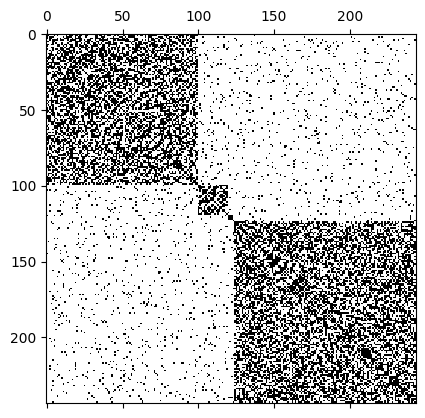

In [20]:
sparse_block_corr_matrix_ground_truth, _ = create_sparse_block_correlation(
    block_sizes=BLOCKS_OTUS, within_density=0.5, between_density=0.05
)
spy(sparse_block_corr_matrix_ground_truth.to_numpy())

In [10]:
sparse_block_absolute_abundance_ground_truth = (
    simulate_absolute_abundances_ground_truth(
        sparse_block_corr_matrix_ground_truth,
        n_sample=N_SAMPLES,
        mean_abundance=500,
        var_abundance=0.1,
        taxa_var_abundance=2,
    )
)
sparse_block_absolute_abundance_ground_truth

,OTU_1,OTU_2,OTU_3,OTU_4,OTU_5,OTU_6,OTU_7,OTU_8,OTU_9,OTU_10,...,OTU_235,OTU_236,OTU_237,OTU_238,OTU_239,OTU_240,OTU_241,OTU_242,OTU_243,OTU_244
Sample0,46.283069,124.694526,218.033967,1255.244215,367.499242,2102.190159,534.510097,335.815562,45.158775,55.821253,...,93.192198,300.285701,119.446623,278.217368,158.442529,256.180887,1977.452140,23.965906,3030.946551,1024.281279
Sample1,50.554369,114.371009,265.416456,1021.367399,102.913213,1649.384202,400.489302,337.094404,64.442420,40.000006,...,45.280953,576.914650,303.873914,430.040133,263.832552,402.764715,1332.215645,53.435586,2849.939625,348.569146
Sample2,40.264810,93.970908,191.903373,913.624780,68.226247,2571.243181,643.608541,205.283598,29.210820,48.632817,...,45.116779,446.968825,83.553567,225.757361,273.906923,230.767580,2107.942284,55.508435,3157.937505,465.117112
Sample3,37.994181,125.005752,217.493429,1337.832585,126.598886,3037.492601,442.537724,160.483606,42.144417,30.319087,...,71.995310,515.370274,170.548137,218.712848,120.454123,274.827666,1361.279139,83.755817,2243.499293,392.456676
Sample4,50.529103,228.347576,330.840403,972.664350,158.252241,2084.898723,563.361986,261.357329,35.192306,45.217055,...,99.181197,601.706036,155.792467,359.425848,327.245665,400.517460,1979.212366,33.512441,2818.303700,611.330085
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Sample995,56.432256,145.738806,208.166886,1130.476355,112.709184,1150.092254,550.942971,203.672035,39.847063,29.796994,...,105.664956,420.576297,99.947932,379.394954,300.020933,481.874542,1756.149584,22.835102,2791.432985,376.980382
Sample996,50.826306,284.738900,386.718468,1090.300677,174.001380,3397.420703,285.189503,405.942950,26.599281,33.975880,...,79.818010,391.160970,102.569194,301.123516,197.839466,309.719199,2841.456579,37.863352,2186.616537,459.998153
Sample997,51.264256,220.685031,169.912831,1387.932057,254.425393,2242.855945,455.642443,321.741221,71.981400,26.221543,...,108.485058,1092.363998,120.643827,604.195071,241.730777,245.938071,2020.046337,36.559378,3011.563968,642.459332
Sample998,48.316506,153.612961,234.404096,1527.348168,244.786471,2044.995793,534.669950,425.104771,33.134787,50.040128,...,106.202245,493.755391,92.667655,297.257670,183.186447,305.796284,2391.094655,68.245690,2674.087757,348.548541


In [11]:
sparse_block_sequencing_df = simulate_sequencing(
    block_absolute_abundance_ground_truth,
    sequencing_depth=N_COUNTS_PER_SAMPLE,
)
sparse_block_sequencing_df

,OTU_1,OTU_2,OTU_3,OTU_4,OTU_5,OTU_6,OTU_7,OTU_8,OTU_9,OTU_10,...,OTU_235,OTU_236,OTU_237,OTU_238,OTU_239,OTU_240,OTU_241,OTU_242,OTU_243,OTU_244
Sample0,2,1,0,4,0,10,3,1,11,1,...,0,2,2,3,0,1,1,1,0,31
Sample1,0,1,0,7,0,18,5,0,2,1,...,0,6,5,1,0,0,0,2,0,29
Sample2,1,2,0,1,0,3,4,0,2,1,...,0,1,8,1,0,1,2,0,0,37
Sample3,0,5,0,2,0,7,8,1,2,0,...,1,3,1,1,2,0,0,0,1,18
Sample4,0,3,0,5,0,10,3,0,3,2,...,0,6,5,3,1,0,0,0,2,23
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Sample995,0,1,1,2,0,4,7,2,1,0,...,0,8,7,1,0,0,1,5,1,37
Sample996,1,2,0,3,1,6,3,0,1,2,...,0,1,5,0,1,1,0,0,1,19
Sample997,1,0,0,3,0,6,2,0,2,1,...,0,4,3,0,1,3,0,2,3,42
Sample998,2,0,0,6,0,9,4,2,0,5,...,0,1,4,1,1,0,0,0,2,51
